In [7]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from debug.qm_env_plots import plot_results
from environments.classes.lindblad_env import Lindblad_Environment
from environments.qm_env_wrapper import GymEnvironment
from serialization.serialize_experiment import load_experiment, read_experiment_metadata
from utils.evaluate import get_control_sequence


In [8]:
EXPERIMENT_ID = "2026-11-16T20-54-35-535476Z"

metadata = read_experiment_metadata(EXPERIMENT_ID)

ENV_PARAMS = metadata["env_params"]
HYPER_PARAMS = metadata["hyper_params"]

seed = metadata["seed"]

In [9]:
env = Lindblad_Environment(params=ENV_PARAMS)

gym_env = GymEnvironment(env, HYPER_PARAMS)

In [10]:
agent, _ = load_experiment(EXPERIMENT_ID, gym_env)

In [11]:
times, actions, final_info = get_control_sequence(gym_env, agent, seed = seed)

history = env.replay(actions)

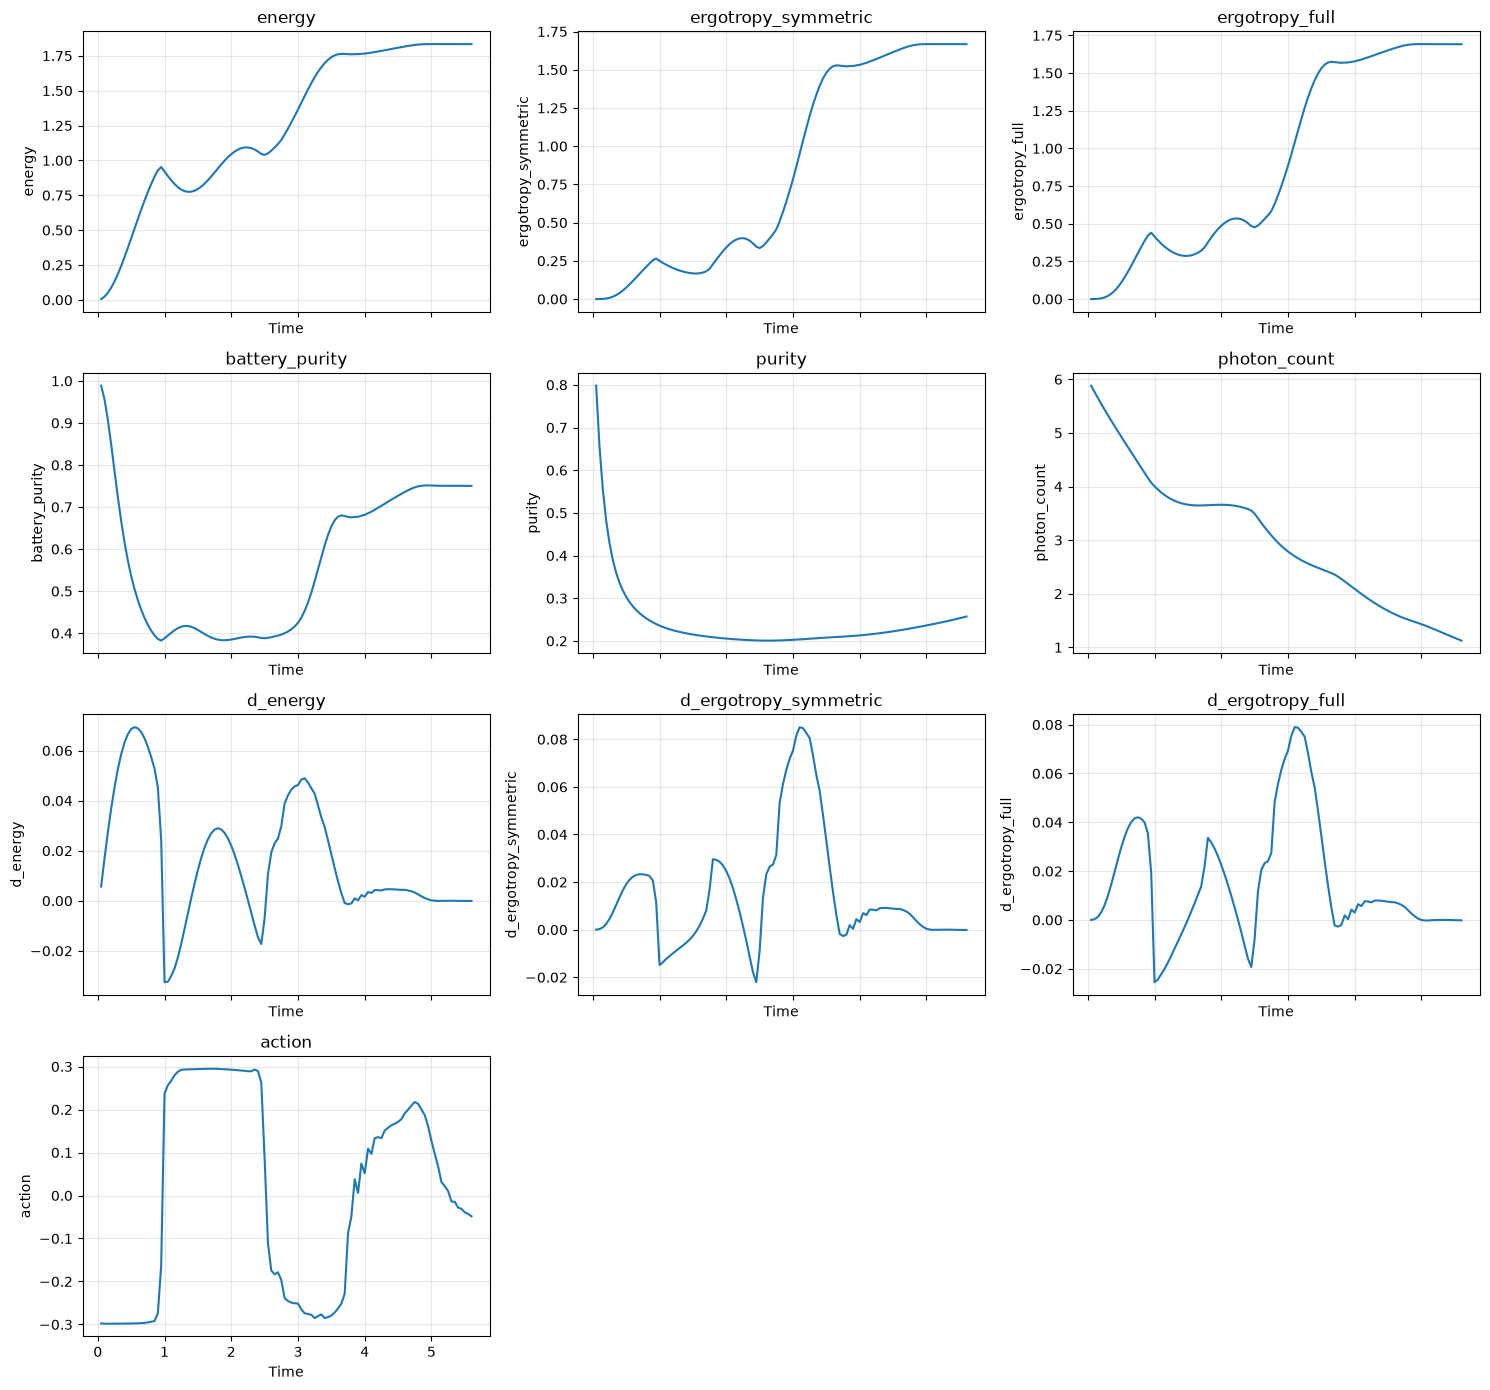

In [12]:
plot_results(history)